# Regresion sobre la duracion del flujo (CIC-IDS2017)

**Objetivo continuo:** `log1p(Flow Duration)`. **Modelos:** Ridge (baseline), Decision Tree Regressor y Random Forest Regressor.

Version pensada para correr en **unos 10-15 minutos en Colab**: se omiten los graficos de EDA y los modelos de clasificacion, se entrena con una submuestra estratificada del train y se evalua en el **test completo** (mismo split 80/20 estratificado de la clasificacion, `SEED = 67`).

Fugas de informacion: se eliminan las columnas que se calculan a partir de la duracion (`IAT`, `Packets/s`, `Bytes/s`, `Active`, `Idle`).

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
warnings.filterwarnings('ignore')

path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")
dfs = []
for f in glob.glob(os.path.join(path, "*.csv")):
    d = pd.read_csv(f)
    d.columns = d.columns.str.strip()      # los nombres traen espacios al inicio
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
del dfs
print("Dataset completo:", df.shape)

Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.
Dataset completo: (2830743, 79)


In [2]:
# Misma limpieza que en clasificacion: inf -> NaN y se eliminan esas filas
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
df = df.loc[~df[num_cols].isna().any(axis=1)].reset_index(drop=True)
df[num_cols] = df[num_cols].astype('float32')     # menos memoria y entrenamiento mas rapido
print("Shape despues de la limpieza:", df.shape)

Shape despues de la limpieza: (2827876, 79)


In [3]:
from sklearn.model_selection import train_test_split

# Mismo split que en clasificacion (estratificado por familia de ataque) para poder comparar
def familia(etiqueta):
    if etiqueta == 'BENIGN':            return 'BENIGN'
    if etiqueta.startswith('DoS'):      return 'DoS'
    if etiqueta == 'DDoS':              return 'DDoS'
    if etiqueta == 'PortScan':          return 'PortScan'
    if etiqueta in ('FTP-Patator', 'SSH-Patator'): return 'Brute Force'
    if etiqueta.startswith('Web Attack'): return 'Web Attack'
    if etiqueta == 'Bot':               return 'Bot'
    return 'Raras'

df['Label_multi'] = df['Label'].map(familia)
nombres_clases = df['Label_multi'].value_counts().index.tolist()
df['Label_multi_id'] = df['Label_multi'].map({c: i for i, c in enumerate(nombres_clases)})

SEED = 67
idx_tr, idx_te = train_test_split(df.index, test_size=0.2,
                                  stratify=df['Label_multi_id'], random_state=SEED)
print("Train:", len(idx_tr), " Test:", len(idx_te))

Train: 2262300  Test: 565576


In [4]:
# Variable objetivo y features (sin fugas de informacion)
LEAK_KEYS = ['IAT', 'Packets/s', 'Bytes/s', 'Active', 'Idle']
fugas = [c for c in num_cols if any(k in c for k in LEAK_KEYS)]
excluir = ['Flow Duration'] + fugas
FEATURES_REG = [c for c in num_cols if c not in excluir]
print(f"{len(fugas)} columnas eliminadas por fuga:", fugas)
print(f"{len(FEATURES_REG)} features para regresion")

def preparar(idx):
    s = df.loc[idx]
    neg = (s['Flow Duration'] < 0).sum()          # hay duraciones negativas en el dataset
    s = s[s['Flow Duration'] >= 0]
    X = s[FEATURES_REG].values
    y = np.log1p(s['Flow Duration'].values.astype('float64'))
    return X, y, s['Label_multi'].values, neg

X_train, y_train, fam_train, neg_tr = preparar(idx_tr)
X_test,  y_test,  fam_test,  neg_te = preparar(idx_te)
print(f"Filas con duracion negativa descartadas: train {neg_tr}, test {neg_te}")
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"log1p(Flow Duration): media {y_train.mean():.2f}, std {y_train.std():.2f}")

26 columnas eliminadas por fuga: ['Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Packets/s', 'Bwd Packets/s', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
51 features para regresion
Filas con duracion negativa descartadas: train 91, test 24
Train: (2262209, 51)  Test: (565552, 51)
log1p(Flow Duration): media 9.94, std 5.46


In [5]:
# Submuestras estratificadas por familia (conservan un minimo de filas de las clases raras)
def indices_estratificados(y, n, minimo_por_clase=0, seed=SEED):
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    clases, conteos = np.unique(y, return_counts=True)
    cuota = np.round(conteos / conteos.sum() * n).astype(int)
    cuota = np.maximum(cuota, np.minimum(minimo_por_clase, conteos))
    cuota = np.minimum(cuota, conteos)
    idx = [rng.choice(np.where(y == c)[0], size=q, replace=False) for c, q in zip(clases, cuota)]
    idx = np.concatenate(idx)
    rng.shuffle(idx)
    return idx

TRAIN_N  = 150_000    # filas con las que se entrenan los modelos finales
SEARCH_N = 30_000     # filas para la busqueda de hiperparametros

idx_fit = indices_estratificados(fam_train, TRAIN_N, 200)
Xf, yf = X_train[idx_fit], y_train[idx_fit]
idx_s = indices_estratificados(fam_train, SEARCH_N, 100)
Xs, ys = X_train[idx_s], y_train[idx_s]
print("Entrenamiento final:", Xf.shape, " Busqueda:", Xs.shape)

Entrenamiento final: (150216, 51)  Busqueda: (30193, 51)


## Exploracion de hiperparametros

`RandomizedSearchCV` con validacion cruzada de 3 folds y `scoring='neg_mean_absolute_error'` sobre una submuestra del **train** (el test no se usa para elegir).

In [6]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
busquedas = {
    'Decision Tree': (DecisionTreeRegressor(random_state=SEED),
                      {'max_depth': [5, 10, 15, 20, 30, None],
                       'min_samples_leaf': [1, 2, 5, 10, 20, 50],
                       'max_features': [None, 0.5]}, 12, -1),
    'Random Forest': (RandomForestRegressor(n_estimators=40, n_jobs=-1, random_state=SEED),
                      {'max_depth': [10, 20, None],
                       'min_samples_leaf': [1, 2, 5, 10],
                       'max_features': [0.3, 0.5, 1.0]}, 6, 1),   # el bosque ya usa todos los nucleos
}

busqueda_res = {}
for nombre, (modelo, espacio, n_iter, nj) in busquedas.items():
    t0 = time.perf_counter()
    b = RandomizedSearchCV(modelo, espacio, n_iter=n_iter, cv=cv, scoring='neg_mean_absolute_error',
                           n_jobs=nj, random_state=SEED, refit=False)
    b.fit(Xs, ys)
    busqueda_res[nombre] = b
    print(f"{nombre}: MAE CV = {-b.best_score_:.4f} | {time.perf_counter() - t0:.0f}s | {b.best_params_}")

Decision Tree: MAE CV = 1.1916 | 14s | {'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15}
Random Forest: MAE CV = 1.1193 | 76s | {'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 20}


## Modelos finales y metricas en test

Metricas en **escala log1p**: MAE, RMSE y R². `factor_error = exp(MAE)` indica por cuantas veces se equivoca el modelo, en promedio, al predecir la duracion real.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def log_signed(X):
    X = np.asarray(X, dtype=float)
    return np.sign(X) * np.log1p(np.abs(X))

modelos = {
    'Ridge (baseline)': make_pipeline(FunctionTransformer(log_signed), StandardScaler(), Ridge(alpha=1.0)),
    'Decision Tree': DecisionTreeRegressor(random_state=SEED, **busqueda_res['Decision Tree'].best_params_),
    'Random Forest': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED,
                                           **busqueda_res['Random Forest'].best_params_),
}

filas, preds = [], {}
for nombre, m in modelos.items():
    t0 = time.perf_counter(); m.fit(Xf, yf); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = m.predict(X_test); t_pred = time.perf_counter() - t0
    preds[nombre] = p
    mae = mean_absolute_error(y_test, p)
    filas.append({'Modelo': nombre, 'MAE': mae,
                  'RMSE': mean_squared_error(y_test, p) ** 0.5,
                  'R2': r2_score(y_test, p), 'factor_error': np.exp(mae),
                  'fit_s': t_fit, 'predict_s': t_pred})
    print(f"{nombre} listo (fit {t_fit:.0f}s, predict {t_pred:.0f}s)")

resultados_reg = pd.DataFrame(filas).set_index('Modelo')
display(resultados_reg.round(4))
mejor = resultados_reg['R2'].idxmax()
print("Mejor modelo por R2:", mejor)

Ridge (baseline) listo (fit 0s, predict 1s)
Decision Tree listo (fit 4s, predict 0s)
Random Forest listo (fit 75s, predict 13s)


,MAE,RMSE,R2,factor_error,fit_s,predict_s
Modelo,,,,,,
Ridge (baseline),2.4003,2.9853,0.7010,11.0268,0.3617,0.7649
Decision Tree,1.0767,1.7239,0.9003,2.9349,4.1003,0.1378
Random Forest,0.9813,1.5740,0.9169,2.6678,74.8445,13.1064


Mejor modelo por R2: Random Forest


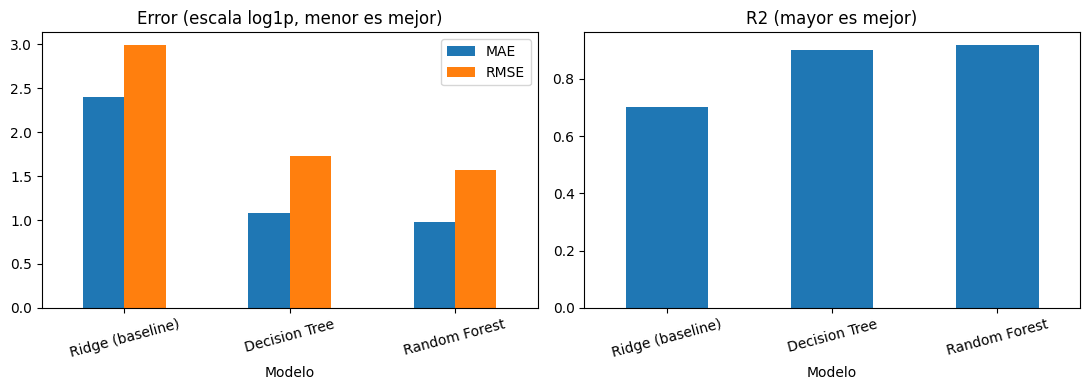

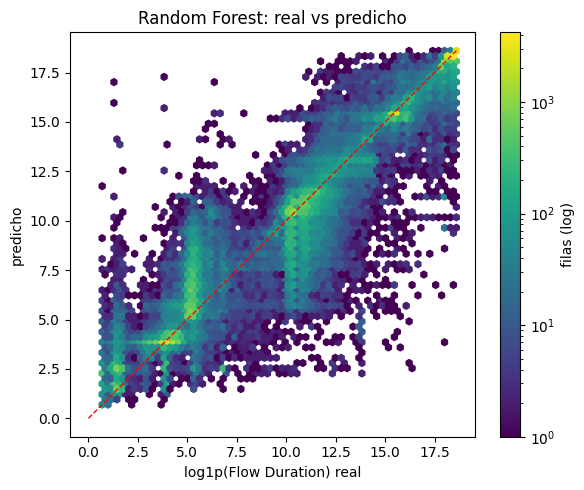

In [8]:
# 1) Comparacion de metricas
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
resultados_reg[['MAE', 'RMSE']].plot(kind='bar', ax=axes[0], title='Error (escala log1p, menor es mejor)')
resultados_reg[['R2']].plot(kind='bar', ax=axes[1], title='R2 (mayor es mejor)', legend=False)
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

# 2) Real vs predicho del mejor modelo (muestra del test)
rng = np.random.default_rng(SEED)
i = rng.choice(len(y_test), size=min(100_000, len(y_test)), replace=False)
plt.figure(figsize=(6, 5))
plt.hexbin(y_test[i], preds[mejor][i], gridsize=60, bins='log', mincnt=1, cmap='viridis')
lim = [0, y_test.max()]
plt.plot(lim, lim, 'r--', lw=1)
plt.xlabel('log1p(Flow Duration) real'); plt.ylabel('predicho')
plt.title(f'{mejor}: real vs predicho'); plt.colorbar(label='filas (log)')
plt.tight_layout()
plt.show()

,MAE,filas
familia,,
Brute Force,0.2045,2766
Bot,0.2919,391
PortScan,0.3823,31761
Web Attack,0.4063,436
DoS,0.5874,50343
DDoS,0.8798,25605
Raras,1.0045,9
BENIGN,1.0784,454241


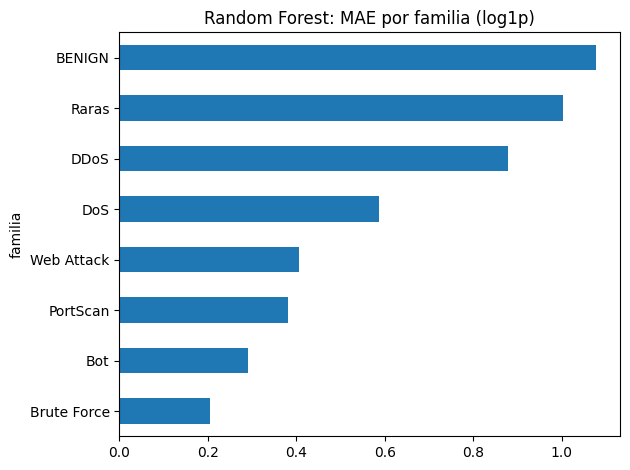

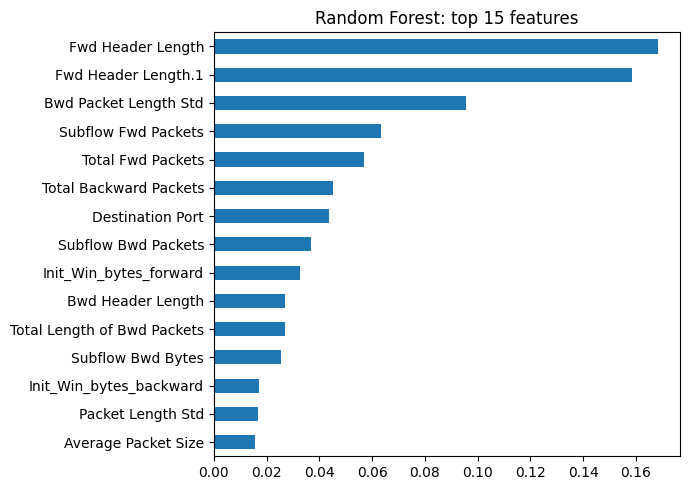

In [9]:
# 3) Error por familia de trafico (mejor modelo): donde falla el regresor?
err = pd.DataFrame({'familia': fam_test, 'error_abs': np.abs(y_test - preds[mejor])})
por_familia = err.groupby('familia')['error_abs'].agg(MAE='mean', filas='count').sort_values('MAE')
display(por_familia.round(4))
por_familia['MAE'].plot(kind='barh', title=f'{mejor}: MAE por familia (log1p)')
plt.tight_layout()
plt.show()

# 4) Importancia de features del Random Forest
rf = modelos['Random Forest']
imp = pd.Series(rf.feature_importances_, index=FEATURES_REG).sort_values().tail(15)
imp.plot(kind='barh', figsize=(7, 5), title='Random Forest: top 15 features')
plt.tight_layout()
plt.show()

### Conclusiones (completar tras correr)

- **Modelo ganador y R2:** ...
- **Si el R2 del Ridge ya es muy alto:** revisar si queda alguna fuga en las features (ver la importancia del Random Forest).
- **Familias con mas error:** ...
- **Limitaciones:** se entrena con una submuestra de 150.000 filas y las metricas estan en escala log1p.